In [1]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nProject files:")
print(os.listdir(".."))

print("\nRaw dataset files:")
print(os.listdir("../data/raw"))

Current working directory:
/Users/sandarunipuna/Projects/hm-recommendation-engine/notebooks

Project files:
['.DS_Store', 'app', 'requirements.txt', 'models', '.gitignore', 'figures', '.venv', '.git', 'data', 'notebooks', 'reports', 'src']

Raw dataset files:
['customers.csv', 'articles.csv', 'transactions_train.csv']


In [2]:
import pandas as pd
from pathlib import Path

# Dataset paths
DATA_DIR = Path("../data")
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"

TRANSACTIONS_PATH = RAW_DIR / "transactions_train.csv"

# Chronological split boundaries
TRAIN_END = "2020-07-31"
VALIDATION_START = "2020-08-01"
VALIDATION_END = "2020-08-31"
TEST_START = "2020-09-01"
TEST_END = "2020-09-22"

print("TRAINING:      2018-09-20 to", TRAIN_END)
print("VALIDATION:   ", VALIDATION_START, "to", VALIDATION_END)
print("TEST:         ", TEST_START, "to", TEST_END)

print("\nTransaction file exists:", TRANSACTIONS_PATH.exists())

TRAINING:      2018-09-20 to 2020-07-31
VALIDATION:    2020-08-01 to 2020-08-31
TEST:          2020-09-01 to 2020-09-22

Transaction file exists: True


In [3]:
# Count transactions using memory-efficient chunk processing

split_counts = {
    "Training": 0,
    "Validation": 0,
    "Testing": 0
}

total_transactions = 0
min_date = None
max_date = None
outside_period = 0

for chunk in pd.read_csv(
    TRANSACTIONS_PATH,
    usecols=["t_dat"],
    chunksize=1_000_000,
    dtype={"t_dat": "string"}
):
    dates = chunk["t_dat"]

    total_transactions += len(chunk)

    chunk_min = dates.min()
    chunk_max = dates.max()

    min_date = chunk_min if min_date is None else min(min_date, chunk_min)
    max_date = chunk_max if max_date is None else max(max_date, chunk_max)

    split_counts["Training"] += (
        (dates >= "2018-09-20") & (dates <= TRAIN_END)
    ).sum()

    split_counts["Validation"] += (
        (dates >= VALIDATION_START) & (dates <= VALIDATION_END)
    ).sum()

    split_counts["Testing"] += (
        (dates >= TEST_START) & (dates <= TEST_END)
    ).sum()

    outside_period += (
        (dates < "2018-09-20") | (dates > TEST_END)
    ).sum()

print("TRANSACTION DATE RANGE")
print("======================")
print("Earliest:", min_date)
print("Latest:", max_date)

print("\nTRANSACTION SPLIT SUMMARY")
print("=========================")

for split, count in split_counts.items():
    percentage = count / total_transactions * 100
    print(f"{split:12}: {count:>12,} ({percentage:.2f}%)")

print(f"\nTotal transactions: {total_transactions:,}")
print(f"Outside defined period: {outside_period:,}")
print(
    "Split count matches total:",
    sum(split_counts.values()) + outside_period == total_transactions
)

TRANSACTION DATE RANGE
Earliest: 2018-09-20
Latest: 2020-09-22

TRANSACTION SPLIT SUMMARY
Training    :   29,752,863 (93.60%)
Validation  :    1,237,192 (3.89%)
Testing     :      798,269 (2.51%)

Total transactions: 31,788,324
Outside defined period: 0
Split count matches total: True


In [4]:
import psutil

memory = psutil.virtual_memory()

print("SYSTEM MEMORY")
print("======================")
print(f"Total RAM:     {memory.total / (1024**3):.2f} GB")
print(f"Available RAM: {memory.available / (1024**3):.2f} GB")
print(f"Used RAM:      {memory.percent}%")

print("\nTRANSACTION DATA")
print("======================")
print(f"Total rows: {total_transactions:,}")

SYSTEM MEMORY
Total RAM:     16.00 GB
Available RAM: 3.69 GB
Used RAM:      76.9%

TRANSACTION DATA
Total rows: 31,788,324


In [5]:
import pandas as pd

sample = pd.read_csv(TRANSACTIONS_PATH, nrows=5)

print("TRANSACTION SAMPLE")
print("==============================")
display(sample)

print("\nDATA TYPES")
print("==============================")
print(sample.dtypes)

print("\nMEMORY USAGE")
print("==============================")
print(sample.memory_usage(deep=True))

TRANSACTION SAMPLE


,t_dat,customer_id,article_id,price,sales_channel_id
0,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,663713001,0.050831,2
1,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,541518023,0.030492,2
2,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,505221004,0.015237,2
3,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,685687003,0.016932,2
4,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,685687004,0.016932,2



DATA TYPES
t_dat                   str
customer_id             str
article_id            int64
price               float64
sales_channel_id      int64
dtype: object

MEMORY USAGE
Index               132
t_dat               295
customer_id         565
article_id           40
price                40
sales_channel_id     40
dtype: int64


In [6]:
optimized_dtypes = {
    "customer_id": "string",
    "article_id": "int32",
    "price": "float32",
    "sales_channel_id": "int8"
}

test_data = pd.read_csv(
    TRANSACTIONS_PATH,
    nrows=100_000,
    dtype=optimized_dtypes,
    parse_dates=["t_dat"]
)

print("OPTIMIZED DATA TYPES")
print("==============================")
print(test_data.dtypes)

print("\nMEMORY USAGE")
print("==============================")
print(
    f"{test_data.memory_usage(deep=True).sum() / (1024**2):.2f} MB"
)

print("\nDATA SAMPLE")
display(test_data.head())

OPTIMIZED DATA TYPES
t_dat               datetime64[us]
customer_id                 string
article_id                   int32
price                      float32
sales_channel_id              int8
dtype: object

MEMORY USAGE
12.40 MB

DATA SAMPLE


,t_dat,customer_id,article_id,price,sales_channel_id
0,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,663713001,0.050831,2
1,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,541518023,0.030492,2
2,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,505221004,0.015237,2
3,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,685687003,0.016932,2
4,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,685687004,0.016932,2


In [7]:
chunk_size = 500_000

transaction_reader = pd.read_csv(
    TRANSACTIONS_PATH,
    dtype=optimized_dtypes,
    parse_dates=["t_dat"],
    chunksize=chunk_size
)

first_chunk = next(transaction_reader)

print("FIRST CHUNK")
print("==============================")
print(f"Rows: {len(first_chunk):,}")
print(f"Memory: {first_chunk.memory_usage(deep=True).sum() / (1024**2):.2f} MB")

display(first_chunk.head())

FIRST CHUNK
Rows: 500,000
Memory: 61.99 MB


,t_dat,customer_id,article_id,price,sales_channel_id
0,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,663713001,0.050831,2
1,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,541518023,0.030492,2
2,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,505221004,0.015237,2
3,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,685687003,0.016932,2
4,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,685687004,0.016932,2


In [8]:
second_chunk = next(transaction_reader)

print("SECOND CHUNK")
print("==============================")
print(f"Rows: {len(second_chunk):,}")
print(f"First date: {second_chunk['t_dat'].min()}")
print(f"Last date:  {second_chunk['t_dat'].max()}")
print(f"Memory: {second_chunk.memory_usage(deep=True).sum() / (1024**2):.2f} MB")

SECOND CHUNK
Rows: 500,000
First date: 2018-09-29 00:00:00
Last date:  2018-10-11 00:00:00
Memory: 61.99 MB


In [9]:
transaction_reader = pd.read_csv(
    TRANSACTIONS_PATH,
    dtype=optimized_dtypes,
    parse_dates=["t_dat"],
    chunksize=chunk_size
)

print("Reader reset successfully.")
print(f"Chunk size: {chunk_size:,}")
print(f"Expected total rows: {total_transactions:,}")

Reader reset successfully.
Chunk size: 500,000
Expected total rows: 31,788,324


In [10]:
try:
    import duckdb
    print("DuckDB is installed.")
    print("Version:", duckdb.__version__)
except ImportError:
    print("DuckDB is not installed.")

DuckDB is installed.
Version: 2.0.1


In [11]:
%pip install duckdb

Note: you may need to restart the kernel to use updated packages.


In [12]:
import duckdb

print("DuckDB version:", duckdb.__version__)

DuckDB version: 2.0.1


In [13]:
import duckdb
import os

DB_PATH = "../data/processed/hm_recommendations.duckdb"

os.makedirs("../data/processed", exist_ok=True)

con = duckdb.connect(DB_PATH)

print("Database created successfully.")
print("Database path:", os.path.abspath(DB_PATH))

Database created successfully.
Database path: /Users/sandarunipuna/Projects/hm-recommendation-engine/data/processed/hm_recommendations.duckdb


In [14]:
TRANSACTIONS_PATH = "../data/raw/transactions_train.csv"

con.execute(f"""
    CREATE OR REPLACE VIEW transactions AS
    SELECT
        CAST(t_dat AS DATE) AS t_dat,
        customer_id,
        article_id,
        price,
        sales_channel_id
    FROM read_csv_auto('{TRANSACTIONS_PATH}')
""")

print("Transaction view created successfully.")

Transaction view created successfully.


In [15]:
result = con.execute("""
    SELECT
        COUNT(*) AS total_transactions,
        COUNT(DISTINCT customer_id) AS unique_customers,
        COUNT(DISTINCT article_id) AS unique_articles,
        MIN(t_dat) AS earliest_date,
        MAX(t_dat) AS latest_date
    FROM transactions
""").df()

display(result)

,total_transactions,unique_customers,unique_articles,earliest_date,latest_date
0,31788324,1362281,104547,2018-09-20,2020-09-22


In [16]:
con.execute("""
    CREATE OR REPLACE TABLE train_transactions AS
    SELECT *
    FROM transactions
    WHERE t_dat <= DATE '2020-07-31';

    CREATE OR REPLACE TABLE validation_transactions AS
    SELECT *
    FROM transactions
    WHERE t_dat BETWEEN DATE '2020-08-01'
                    AND DATE '2020-08-31';

    CREATE OR REPLACE TABLE test_transactions AS
    SELECT *
    FROM transactions
    WHERE t_dat BETWEEN DATE '2020-09-01'
                    AND DATE '2020-09-22';
""")

print("Chronological splits created successfully.")

Chronological splits created successfully.


In [17]:
split_summary = con.execute("""
    SELECT
        'Training' AS dataset,
        COUNT(*) AS transactions,
        MIN(t_dat) AS start_date,
        MAX(t_dat) AS end_date
    FROM train_transactions

    UNION ALL

    SELECT
        'Validation',
        COUNT(*),
        MIN(t_dat),
        MAX(t_dat)
    FROM validation_transactions

    UNION ALL

    SELECT
        'Testing',
        COUNT(*),
        MIN(t_dat),
        MAX(t_dat)
    FROM test_transactions
""").df()

display(split_summary)

total_split = con.execute("""
    SELECT
        (SELECT COUNT(*) FROM train_transactions) +
        (SELECT COUNT(*) FROM validation_transactions) +
        (SELECT COUNT(*) FROM test_transactions)
""").fetchone()[0]

print(f"Total transactions across splits: {total_split:,}")
print(f"Original transactions:            {31_788_324:,}")
print(f"All transactions accounted for:   {total_split == 31_788_324}")

,dataset,transactions,start_date,end_date
0,Training,29752863,2018-09-20,2020-07-31
1,Validation,1237192,2020-08-01,2020-08-31
2,Testing,798269,2020-09-01,2020-09-22


Total transactions across splits: 31,788,324
Original transactions:            31,788,324
All transactions accounted for:   True


In [18]:
customer_activity = con.execute("""
    SELECT
        customer_id,
        COUNT(*) AS total_purchases,
        COUNT(DISTINCT article_id) AS unique_articles,
        COUNT(DISTINCT t_dat) AS active_days,
        SUM(price) AS total_spending
    FROM train_transactions
    GROUP BY customer_id
""").df()

print("Customer activity summary:")
display(customer_activity.describe().round(2))

print("\nSample customers:")
display(customer_activity.head(10))

Customer activity summary:


,total_purchases,unique_articles,active_days,total_spending
count,1321769.00,1321769.00,1321769.00,1321769.00
mean,22.51,19.33,6.39,0.62
std,37.33,30.42,9.14,1.13
min,1.00,1.00,1.00,0.00
25%,3.00,3.00,1.00,0.09
50%,9.00,8.00,3.00,0.24
75%,26.00,23.00,8.00,0.68
max,1761.00,1259.00,388.00,53.41



Sample customers:


,customer_id,total_purchases,unique_articles,active_days,total_spending
0,018206a3b5a6191aa4946a96f5a77e8ff28944cb033b66...,95,53,22,1.803186
1,37b4f5c48fd7e4dcf3ddbb0f7b1c838f206e870cae8a94...,142,74,18,2.805288
2,409bc713dca51b91746a9468042112873a137c6d259c2e...,106,94,42,2.450763
3,512972ab938352aae5977f99c20282c13b8b5007ec74b7...,141,138,55,2.265186
4,7707816b08119032b93db91339b6f3071c5db3646c971e...,37,31,6,0.763458
5,822cb0114a4156f644f7f70348418531467fb9d3a4b251...,320,258,61,9.142814
6,b5add0de394dc7157c8b48065d93ae2bf02775b56ae8b8...,323,231,37,9.490373
7,d17f0f891d1920e6c387ff87004c0a667d7b6103d972e6...,22,20,16,1.168475
8,7806c82b3ce6bf1d654c3f95793af0d6390a1d0bd15628...,31,29,3,0.572356
9,5ae8183e62b99b795d0c097ba4fa80649d8fff41ac10d2...,22,19,9,0.480847


In [19]:
activity_bins = [0, 2, 5, 10, 20, 50, float("inf")]

activity_labels = [
    "1-2 purchases",
    "3-5 purchases",
    "6-10 purchases",
    "11-20 purchases",
    "21-50 purchases",
    "50+ purchases"
]

customer_activity["activity_segment"] = pd.cut(
    customer_activity["total_purchases"],
    bins=activity_bins,
    labels=activity_labels
)

segment_summary = (
    customer_activity["activity_segment"]
    .value_counts()
    .reindex(activity_labels)
    .to_frame(name="customer_count")
)

segment_summary["percentage"] = (
    segment_summary["customer_count"]
    / len(customer_activity) * 100
).round(2)

print("CUSTOMER ACTIVITY SEGMENTATION")
display(segment_summary)

CUSTOMER ACTIVITY SEGMENTATION


,customer_count,percentage
activity_segment,,
1-2 purchases,251341,19.02
3-5 purchases,237080,17.94
6-10 purchases,215660,16.32
11-20 purchases,215444,16.30
21-50 purchases,244415,18.49
50+ purchases,157829,11.94


In [20]:
interaction_stats = con.execute("""
    SELECT
        COUNT(*) AS total_interactions,
        COUNT(DISTINCT customer_id) AS unique_customers,
        COUNT(DISTINCT article_id) AS unique_articles,
        COUNT(DISTINCT (customer_id, article_id)) AS unique_customer_article_pairs
    FROM train_transactions
""").df()

display(interaction_stats)

,total_interactions,unique_customers,unique_articles,unique_customer_article_pairs
0,29752863,1321769,98416,25550610


In [21]:
total_possible_pairs = (
    interaction_stats.loc[0, "unique_customers"]
    * interaction_stats.loc[0, "unique_articles"]
)

observed_pairs = interaction_stats.loc[
    0, "unique_customer_article_pairs"
]

density = observed_pairs / total_possible_pairs
sparsity = 1 - density

print("INTERACTION MATRIX ANALYSIS")
print("=" * 40)

print(f"Total possible cells: {total_possible_pairs:,.0f}")
print(f"Observed interactions: {observed_pairs:,.0f}")
print(f"Matrix density: {density * 100:.6f}%")
print(f"Matrix sparsity: {sparsity * 100:.6f}%")

INTERACTION MATRIX ANALYSIS
Total possible cells: 130,083,217,904
Observed interactions: 25,550,610
Matrix density: 0.019642%
Matrix sparsity: 99.980358%


In [22]:
con.execute("""
    CREATE OR REPLACE TABLE customer_article_interactions AS
    SELECT
        customer_id,
        article_id,
        COUNT(*) AS purchase_count
    FROM train_transactions
    GROUP BY customer_id, article_id
""")

result = con.execute("""
    SELECT
        COUNT(*) AS unique_interactions,
        SUM(purchase_count) AS total_transactions,
        AVG(purchase_count) AS avg_purchases_per_pair,
        MAX(purchase_count) AS maximum_purchases_per_pair
    FROM customer_article_interactions
""").df()

display(result)

,unique_interactions,total_transactions,avg_purchases_per_pair,maximum_purchases_per_pair
0,25550610,29752863.0,1.164468,570


In [23]:
repeat_distribution = con.execute("""
    SELECT
        CASE
            WHEN purchase_count = 1 THEN '1 purchase'
            WHEN purchase_count = 2 THEN '2 purchases'
            WHEN purchase_count BETWEEN 3 AND 5 THEN '3-5 purchases'
            WHEN purchase_count BETWEEN 6 AND 10 THEN '6-10 purchases'
            WHEN purchase_count BETWEEN 11 AND 50 THEN '11-50 purchases'
            ELSE '50+ purchases'
        END AS purchase_frequency,

        COUNT(*) AS customer_article_pairs,
        ROUND(
            COUNT(*) * 100.0 /
            SUM(COUNT(*)) OVER (), 2
        ) AS percentage

    FROM customer_article_interactions
    GROUP BY purchase_frequency
    ORDER BY MIN(purchase_count)
""").df()

display(repeat_distribution)

,purchase_frequency,customer_article_pairs,percentage
0,1 purchase,22253802,87.10
1,2 purchases,2756287,10.79
2,3-5 purchases,503902,1.97
3,6-10 purchases,31282,0.12
4,11-50 purchases,5260,0.02
5,50+ purchases,77,0.00


In [24]:
purchase_count_stats = con.execute("""
    SELECT
        AVG(purchase_count) AS mean,
        MEDIAN(purchase_count) AS median,
        STDDEV(purchase_count) AS std,
        MIN(purchase_count) AS minimum,
        QUANTILE_CONT(purchase_count, 0.90) AS p90,
        QUANTILE_CONT(purchase_count, 0.95) AS p95,
        QUANTILE_CONT(purchase_count, 0.99) AS p99,
        MAX(purchase_count) AS maximum
    FROM customer_article_interactions
""").df()

display(purchase_count_stats)

,mean,median,std,minimum,p90,p95,p99,maximum
0,1.164468,1.0,0.573916,1,2.0,2.0,3.0,570


In [25]:
ARTICLES_PATH = "../data/raw/articles.csv"

con.execute(f"""
    CREATE OR REPLACE VIEW articles AS
    SELECT *
    FROM read_csv_auto('{ARTICLES_PATH}')
""")

print("Articles view created successfully.")

display(
    con.execute("SELECT * FROM articles LIMIT 5").df()
)

Articles view created successfully.


,article_id,product_code,prod_name,product_type_no,product_type_name,product_group_name,graphical_appearance_no,graphical_appearance_name,colour_group_code,colour_group_name,...,department_name,index_code,index_name,index_group_no,index_group_name,section_no,section_name,garment_group_no,garment_group_name,detail_desc
0,0108775015,0108775,Strap top,253,Vest top,Garment Upper body,1010016,Solid,09,Black,...,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
1,0108775044,0108775,Strap top,253,Vest top,Garment Upper body,1010016,Solid,10,White,...,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
2,0108775051,0108775,Strap top (1),253,Vest top,Garment Upper body,1010017,Stripe,11,Off White,...,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
3,0110065001,0110065,OP T-shirt (Idro),306,Bra,Underwear,1010016,Solid,09,Black,...,Clean Lingerie,B,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulde..."
4,0110065002,0110065,OP T-shirt (Idro),306,Bra,Underwear,1010016,Solid,10,White,...,Clean Lingerie,B,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulde..."


In [26]:
top_repeat_pairs = con.execute("""
    SELECT
        LEFT(t.customer_id, 12) AS customer_id_sample,
        t.article_id,
        a.prod_name,
        a.product_type_name,
        COUNT(*) AS purchase_count,
        COUNT(DISTINCT t.t_dat) AS distinct_purchase_days,
        MIN(t.t_dat) AS first_purchase,
        MAX(t.t_dat) AS last_purchase

    FROM train_transactions t

    LEFT JOIN articles a
        ON t.article_id = a.article_id

    GROUP BY
        t.customer_id,
        t.article_id,
        a.prod_name,
        a.product_type_name

    ORDER BY purchase_count DESC

    LIMIT 20
""").df()

display(top_repeat_pairs)

,customer_id_sample,article_id,prod_name,product_type_name,purchase_count,distinct_purchase_days,first_purchase,last_purchase
0,d00063b94dcb,0678342001,Lima SS.,T-shirt,570,1,2018-10-14,2018-10-14
1,94665b46e194,0629420001,claudine,T-shirt,199,1,2019-02-16,2019-02-16
2,61da44a27582,0507909001,Rebecca or Delphine shirt,Shirt,188,3,2019-02-21,2019-04-15
3,ef38ec0f0cb2,0570002001,ROY SLIM RN T-SHIRT,T-shirt,170,2,2019-01-17,2019-02-04
4,5cba04ed9a37,0688558002,Brittany LS,Top,166,2,2019-09-25,2019-09-28
5,ebc0f8352482,0685347001,Duo,Top,130,1,2019-04-15,2019-04-15
6,ce79a54991bb,0570004009,PETER POLO,Polo shirt,124,3,2019-06-11,2019-07-04
7,8f5f1e993eff,0189634001,Long Leg Leggings,Leggings/Tights,120,1,2019-02-11,2019-02-11
8,d5902b052374,0179123001,Long Leggings,Leggings/Tights,120,5,2018-12-25,2020-07-02
9,0152964ef198,0756322001,Lindsay N-slip (W),Night gown,120,1,2019-10-16,2019-10-16


In [27]:
genuine_repeats = con.execute("""
    SELECT
        t.customer_id,
        t.article_id,
        a.prod_name,
        a.product_type_name,
        COUNT(*) AS transaction_rows,
        COUNT(DISTINCT t.t_dat) AS purchase_days,
        MIN(t.t_dat) AS first_purchase,
        MAX(t.t_dat) AS last_purchase

    FROM train_transactions t

    LEFT JOIN articles a
        ON t.article_id = a.article_id

    GROUP BY
        t.customer_id,
        t.article_id,
        a.prod_name,
        a.product_type_name

    HAVING COUNT(DISTINCT t.t_dat) >= 2

    ORDER BY
        purchase_days DESC,
        transaction_rows DESC

    LIMIT 20
""").df()

display(genuine_repeats)

,customer_id,article_id,prod_name,product_type_name,transaction_rows,purchase_days,first_purchase,last_purchase
0,91f3ab5944411eb3f6f79e93ab430f3d4ff92e5a5d4475...,0728162001,Talia (1),T-shirt,96,32,2019-02-03,2020-07-07
1,8d2c33a1b060ce16add06f3742447115e5aaea20e847c1...,0668537001,Doutzen,Jacket,73,25,2018-10-11,2019-05-27
2,9d50687e366b49577c136952613632b9f157cb9051cb71...,0772032001,LS Blossom Tanga,Swimwear bottom,34,23,2019-06-14,2020-06-17
3,4f503f96f0585292eb2535c89cf7392007e70f62968460...,0120129001,Babette long,Leggings/Tights,38,19,2018-09-25,2020-05-24
4,a3813d07c74e6b3dbee979bb3209d87c1dec87ad26038f...,0581298001,Patty flip-flop,Flip flop,33,19,2018-10-13,2019-02-17
5,725e94ded9d679b79c5719052dce66098171b9c202f17d...,0228257001,20 den 2p Tights,Underwear Tights,39,18,2019-01-07,2020-07-26
6,0b19646eedcc9544fac9ab9dc12a5b4efc923913316f4a...,0847180001,DIV Kenzy loose dungaree short,Shorts,38,18,2020-03-27,2020-07-28
7,b57f471aa67ad7ae6413c7c3745028c6b8adba4f28feee...,0228257002,20 den 2p Tights,Underwear Tights,33,18,2018-10-14,2020-07-19
8,91f1cc035b5d3e7f54f7c765bb82754129db9eadab0cd5...,0399223001,Curvy Jeggings HW Ankle,Trousers,19,18,2018-09-29,2020-05-30
9,9d50687e366b49577c136952613632b9f157cb9051cb71...,0758043001,LS Emmy Tanga,Swimwear bottom,45,17,2019-06-20,2020-07-02


In [28]:
repeat_summary = con.execute("""
    WITH customer_article AS (
        SELECT
            customer_id,
            article_id,
            COUNT(*) AS transaction_rows,
            COUNT(DISTINCT t_dat) AS purchase_days
        FROM train_transactions
        GROUP BY customer_id, article_id
    )

    SELECT
        COUNT(*) AS total_customer_article_pairs,

        COUNT(*) FILTER (
            WHERE purchase_days = 1
        ) AS one_time_pairs,

        COUNT(*) FILTER (
            WHERE purchase_days >= 2
        ) AS repeat_pairs,

        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE purchase_days >= 2
            ) / COUNT(*), 2
        ) AS repeat_percentage

    FROM customer_article
""").df()

display(repeat_summary)

,total_customer_article_pairs,one_time_pairs,repeat_pairs,repeat_percentage
0,25550610,24489789,1060821,4.15


In [29]:
repeat_frequency = con.execute("""
    WITH customer_article AS (
        SELECT
            customer_id,
            article_id,
            COUNT(DISTINCT t_dat) AS purchase_days
        FROM train_transactions
        GROUP BY customer_id, article_id
    )

    SELECT
        CASE
            WHEN purchase_days = 1 THEN '1 day'
            WHEN purchase_days = 2 THEN '2 days'
            WHEN purchase_days BETWEEN 3 AND 5 THEN '3-5 days'
            WHEN purchase_days BETWEEN 6 AND 10 THEN '6-10 days'
            ELSE 'More than 10 days'
        END AS frequency_group,

        COUNT(*) AS customer_article_pairs,

        ROUND(
            100.0 * COUNT(*) / SUM(COUNT(*)) OVER (),
            2
        ) AS percentage

    FROM customer_article
    GROUP BY frequency_group

    ORDER BY MIN(purchase_days)
""").df()

display(repeat_frequency)

,frequency_group,customer_article_pairs,percentage
0,1 day,24489789,95.85
1,2 days,968617,3.79
2,3-5 days,90344,0.35
3,6-10 days,1756,0.01
4,More than 10 days,104,0.00


In [30]:
article_quality = con.execute("""
    SELECT
        COUNT(*) AS total_transaction_rows,

        COUNT(*) FILTER (
            WHERE a.article_id IS NOT NULL
        ) AS matched_transaction_rows,

        COUNT(*) FILTER (
            WHERE a.article_id IS NULL
        ) AS unmatched_transaction_rows,

        COUNT(DISTINCT t.article_id) AS transaction_articles,

        COUNT(DISTINCT a.article_id) AS matched_articles,

        COUNT(*) FILTER (
            WHERE a.prod_name IS NULL
        ) AS missing_product_names,

        COUNT(*) FILTER (
            WHERE a.product_type_name IS NULL
        ) AS missing_product_types,

        COUNT(*) FILTER (
            WHERE a.detail_desc IS NULL
        ) AS missing_descriptions

    FROM train_transactions t
    LEFT JOIN articles a
        ON t.article_id = a.article_id
""").df()

display(article_quality)

,total_transaction_rows,matched_transaction_rows,unmatched_transaction_rows,transaction_articles,matched_articles,missing_product_names,missing_product_types,missing_descriptions
0,29752863,29752863,0,98416,98416,0,0,113996


In [31]:
display(article_quality.T)

,0
total_transaction_rows,29752863
matched_transaction_rows,29752863
unmatched_transaction_rows,0
transaction_articles,98416
matched_articles,98416
missing_product_names,0
missing_product_types,0
missing_descriptions,113996


In [32]:
missing_description_stats = con.execute("""
    SELECT
        COUNT(DISTINCT a.article_id) AS articles_with_missing_descriptions,
        COUNT(*) AS affected_transaction_rows
    FROM train_transactions t
    JOIN articles a
        ON t.article_id = a.article_id
    WHERE a.detail_desc IS NULL
""").df()

display(missing_description_stats)

,articles_with_missing_descriptions,affected_transaction_rows
0,415,113996


In [33]:
CUSTOMERS_PATH = "../data/raw/customers.csv"

con.execute(f"""
    CREATE OR REPLACE VIEW customers AS
    SELECT *
    FROM read_csv_auto('{CUSTOMERS_PATH}')
""")

print("Customers view created successfully.")

display(
    con.execute("SELECT * FROM customers LIMIT 5").df()
)

Customers view created successfully.


,customer_id,FN,Active,club_member_status,fashion_news_frequency,age,postal_code
0,00000dbacae5abe5e23885899a1fa44253a17956c6d1c3...,NaN,NaN,ACTIVE,NONE,49,52043ee2162cf5aa7ee79974281641c6f11a68d276429a...
1,0000423b00ade91418cceaf3b26c6af3dd342b51fd051e...,NaN,NaN,ACTIVE,NONE,25,2973abc54daa8a5f8ccfe9362140c63247c5eee03f1d93...
2,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,NaN,NaN,ACTIVE,NONE,24,64f17e6a330a85798e4998f62d0930d14db8db1c054af6...
3,00005ca1c9ed5f5146b52ac8639a40ca9d57aeff4d1bd2...,NaN,NaN,ACTIVE,NONE,54,5d36574f52495e81f019b680c843c443bd343d5ca5b1c2...
4,00006413d8573cd20ed7128e53b7b13819fe5cfc2d801f...,1.0,1.0,ACTIVE,Regularly,52,25fa5ddee9aac01b35208d01736e57942317d756b32ddd...


In [34]:
customer_quality = con.execute("""
    SELECT
        COUNT(*) AS total_customers,
        COUNT(age) AS customers_with_age,
        COUNT(*) - COUNT(age) AS missing_age,
        COUNT(club_member_status) AS customers_with_membership,
        COUNT(*) - COUNT(club_member_status) AS missing_membership,
        COUNT(fashion_news_frequency) AS customers_with_news_frequency,
        COUNT(*) - COUNT(fashion_news_frequency) AS missing_news_frequency
    FROM customers
""").df()

display(customer_quality.T)

,0
total_customers,1371980
customers_with_age,1356119
missing_age,15861
customers_with_membership,1365918
missing_membership,6062
customers_with_news_frequency,1355971
missing_news_frequency,16009


In [35]:
age_stats = con.execute("""
    SELECT
        COUNT(age) AS customers_with_age,
        MIN(age) AS minimum_age,
        MAX(age) AS maximum_age,
        ROUND(AVG(age), 2) AS average_age,
        MEDIAN(age) AS median_age
    FROM customers
""").df()

membership_distribution = con.execute("""
    SELECT
        club_member_status,
        COUNT(*) AS customer_count
    FROM customers
    GROUP BY club_member_status
    ORDER BY customer_count DESC
""").df()

news_distribution = con.execute("""
    SELECT
        fashion_news_frequency,
        COUNT(*) AS customer_count
    FROM customers
    GROUP BY fashion_news_frequency
    ORDER BY customer_count DESC
""").df()

print("AGE STATISTICS")
display(age_stats)

print("CLUB MEMBERSHIP DISTRIBUTION")
display(membership_distribution)

print("FASHION NEWS FREQUENCY")
display(news_distribution)

AGE STATISTICS


,customers_with_age,minimum_age,maximum_age,average_age,median_age
0,1356119,16,99,36.39,32.0


CLUB MEMBERSHIP DISTRIBUTION


,club_member_status,customer_count
0,ACTIVE,1272491
1,PRE-CREATE,92960
2,NaN,6062
3,LEFT CLUB,467


FASHION NEWS FREQUENCY


,fashion_news_frequency,customer_count
0,NONE,877711
1,Regularly,477416
2,NaN,16009
3,Monthly,842
4,None,2


In [36]:
age_segments = con.execute("""
    SELECT
        CASE
            WHEN age BETWEEN 16 AND 24 THEN '16-24'
            WHEN age BETWEEN 25 AND 34 THEN '25-34'
            WHEN age BETWEEN 35 AND 44 THEN '35-44'
            WHEN age BETWEEN 45 AND 54 THEN '45-54'
            WHEN age BETWEEN 55 AND 64 THEN '55-64'
            WHEN age >= 65 THEN '65+'
            ELSE 'Unknown'
        END AS age_group,

        COUNT(*) AS customer_count,

        ROUND(
            100.0 * COUNT(*) / SUM(COUNT(*)) OVER (),
            2
        ) AS percentage

    FROM customers
    GROUP BY age_group
    ORDER BY MIN(age)
""").df()

display(age_segments)

,age_group,customer_count,percentage
0,16-24,357169,26.03
1,25-34,393292,28.67
2,35-44,169041,12.32
3,45-54,253951,18.51
4,55-64,139064,10.14
5,65+,43602,3.18
6,Unknown,15861,1.16


In [37]:
age_purchase_behavior = con.execute("""
    WITH customer_activity AS (
        SELECT
            customer_id,
            COUNT(*) AS total_purchases,
            COUNT(DISTINCT article_id) AS unique_articles,
            SUM(price) AS total_spending
        FROM train_transactions
        GROUP BY customer_id
    ),

    customer_segments AS (
        SELECT
            c.customer_id,
            CASE
                WHEN c.age BETWEEN 16 AND 24 THEN '16-24'
                WHEN c.age BETWEEN 25 AND 34 THEN '25-34'
                WHEN c.age BETWEEN 35 AND 44 THEN '35-44'
                WHEN c.age BETWEEN 45 AND 54 THEN '45-54'
                WHEN c.age BETWEEN 55 AND 64 THEN '55-64'
                WHEN c.age >= 65 THEN '65+'
                ELSE 'Unknown'
            END AS age_group,
            a.total_purchases,
            a.unique_articles,
            a.total_spending
        FROM customers c
        INNER JOIN customer_activity a
            ON c.customer_id = a.customer_id
    )

    SELECT
        age_group,
        COUNT(*) AS customer_count,
        ROUND(AVG(total_purchases), 2) AS avg_purchases,
        ROUND(AVG(unique_articles), 2) AS avg_unique_articles,
        ROUND(AVG(total_spending), 4) AS avg_spending
    FROM customer_segments
    GROUP BY age_group
    ORDER BY MIN(
        CASE age_group
            WHEN '16-24' THEN 1
            WHEN '25-34' THEN 2
            WHEN '35-44' THEN 3
            WHEN '45-54' THEN 4
            WHEN '55-64' THEN 5
            WHEN '65+' THEN 6
            ELSE 7
        END
    )
""").df()

display(age_purchase_behavior)

,age_group,customer_count,avg_purchases,avg_unique_articles,avg_spending
0,16-24,338984,17.80,15.54,0.4577
1,25-34,381518,28.39,24.28,0.7936
2,35-44,163473,23.66,20.13,0.6462
3,45-54,246231,23.25,19.90,0.6606
4,55-64,134343,19.54,16.74,0.5839
5,65+,41822,12.84,11.06,0.3933
6,Unknown,15398,8.61,7.50,0.2332


In [38]:
product_group_analysis = con.execute("""
    SELECT
        a.product_group_name,

        COUNT(*) AS transaction_count,

        COUNT(DISTINCT t.customer_id) AS unique_customers,

        COUNT(DISTINCT t.article_id) AS unique_articles,

        ROUND(SUM(t.price), 4) AS total_sales,

        ROUND(AVG(t.price), 6) AS avg_price

    FROM train_transactions t

    INNER JOIN articles a
        ON t.article_id = a.article_id

    GROUP BY a.product_group_name

    ORDER BY transaction_count DESC

""").df()

display(product_group_analysis)

,product_group_name,transaction_count,unique_customers,unique_articles,total_sales,avg_price
0,Garment Upper body,11720622,1056510,39559,314005.5360,0.026791
1,Garment Lower body,6592662,896259,18529,216171.8622,0.032790
2,Garment Full body,3320071,623757,12492,120718.1327,0.036360
3,Swimwear,2452830,410552,3108,54898.3501,0.022382
4,Underwear,2403162,496121,5132,50573.4758,0.021045
5,Accessories,1496457,471046,10408,23276.5832,0.015554
6,Shoes,708254,259315,4966,27325.2556,0.038581
7,Socks & Tights,643763,255605,2231,7361.7388,0.011435
8,Nightwear,329964,162312,1752,8299.7626,0.025154
9,Unknown,72242,48687,80,1808.3492,0.025032


In [39]:
product_type_analysis = con.execute("""
    SELECT
        a.product_type_name,

        a.product_group_name,

        COUNT(*) AS transaction_count,

        COUNT(DISTINCT t.customer_id) AS unique_customers,

        COUNT(DISTINCT t.article_id) AS unique_articles,

        ROUND(SUM(t.price), 4) AS total_sales,

        ROUND(AVG(t.price), 6) AS avg_price

    FROM train_transactions t

    INNER JOIN articles a
        ON t.article_id = a.article_id

    GROUP BY
        a.product_type_name,
        a.product_group_name

    ORDER BY transaction_count DESC

    LIMIT 30

""").df()

display(product_type_analysis)

,product_type_name,product_group_name,transaction_count,unique_customers,unique_articles,total_sales,avg_price
0,Trousers,Garment Lower body,3936034,710609,10235,140218.9402,0.035624
1,Dress,Garment Full body,3023363,588420,9803,110969.6236,0.036704
2,Sweater,Garment Upper body,2625298,618988,8416,75548.9757,0.028777
3,T-shirt,Garment Upper body,2063232,536088,7555,28130.4044,0.013634
4,Top,Garment Upper body,1466242,482765,3801,29543.9931,0.020149
5,Blouse,Garment Upper body,1419594,425263,3776,40112.7668,0.028257
6,Vest top,Garment Upper body,1333952,407466,2929,20863.9108,0.015641
7,Bra,Underwear,1251000,371950,2087,29819.5160,0.023837
8,Shorts,Garment Lower body,1100495,345344,3916,25882.4559,0.023519
9,Bikini top,Swimwear,1069050,323870,844,24665.6852,0.023073


In [40]:
colour_analysis = con.execute("""
    SELECT
        a.colour_group_name,

        COUNT(*) AS transaction_count,

        COUNT(DISTINCT t.customer_id) AS unique_customers,

        COUNT(DISTINCT t.article_id) AS unique_articles,

        ROUND(SUM(t.price), 4) AS total_sales

    FROM train_transactions t

    INNER JOIN articles a
        ON t.article_id = a.article_id

    GROUP BY a.colour_group_name

    ORDER BY transaction_count DESC

    LIMIT 20

""").df()

display(colour_analysis)

,colour_group_name,transaction_count,unique_customers,unique_articles,total_sales
0,Black,10331604,1070123,20897,288024.6847
1,White,3147446,717877,9221,71222.4146
2,Dark Blue,2090339,603040,11566,61096.6749
3,Light Beige,1162516,431784,3069,37039.0446
4,Blue,1010138,403817,3127,34997.4148
5,Light Blue,856618,372161,2911,26972.5938
6,Beige,832776,352166,2390,26215.6786
7,Light Pink,798708,356932,5495,18442.3165
8,Grey,780606,372787,4165,20265.7712
9,Off White,771270,348559,2544,23806.9542


In [41]:
colour_analysis = con.execute("""
    SELECT
        a.colour_group_name,

        COUNT(*) AS transaction_count,

        COUNT(DISTINCT t.customer_id) AS unique_customers,

        COUNT(DISTINCT t.article_id) AS unique_articles,

        ROUND(SUM(t.price), 4) AS total_sales

    FROM train_transactions t

    INNER JOIN articles a
        ON t.article_id = a.article_id

    GROUP BY a.colour_group_name

    ORDER BY transaction_count DESC

    LIMIT 20

""").df()

display(colour_analysis)

,colour_group_name,transaction_count,unique_customers,unique_articles,total_sales
0,Black,10331604,1070123,20897,288024.6847
1,White,3147446,717877,9221,71222.4146
2,Dark Blue,2090339,603040,11566,61096.6749
3,Light Beige,1162516,431784,3069,37039.0446
4,Blue,1010138,403817,3127,34997.4148
5,Light Blue,856618,372161,2911,26972.5938
6,Beige,832776,352166,2390,26215.6786
7,Light Pink,798708,356932,5495,18442.3165
8,Grey,780606,372787,4165,20265.7712
9,Off White,771270,348559,2544,23806.9542


In [42]:
appearance_analysis = con.execute("""
    SELECT
        a.graphical_appearance_name,

        COUNT(*) AS transaction_count,

        COUNT(DISTINCT t.customer_id) AS unique_customers,

        COUNT(DISTINCT t.article_id) AS unique_articles,

        ROUND(SUM(t.price), 4) AS total_sales

    FROM train_transactions t

    INNER JOIN articles a
        ON t.article_id = a.article_id

    GROUP BY a.graphical_appearance_name

    ORDER BY transaction_count DESC

    LIMIT 20

""").df()

display(appearance_analysis)

,graphical_appearance_name,transaction_count,unique_customers,unique_articles,total_sales
0,Solid,16588391,1190269,46146,456080.0991
1,All over pattern,3783749,734368,16310,96901.3569
2,Denim,1826019,496937,4398,70490.6729
3,Melange,1769502,559916,5421,50373.4514
4,Stripe,1392677,469050,4822,32378.6096
5,Other structure,680050,282976,1360,18846.4591
6,Lace,564939,243536,1465,15996.3955
7,Check,547897,262205,1956,19038.9800
8,Placement print,407608,225776,2893,8167.5871
9,Front print,311718,175350,3045,5581.6483


In [43]:
department_analysis = con.execute("""
    SELECT
        a.department_name,
        COUNT(*) AS transaction_count,
        COUNT(DISTINCT t.customer_id) AS unique_customers,
        COUNT(DISTINCT t.article_id) AS unique_articles,
        ROUND(SUM(t.price), 4) AS total_sales

    FROM train_transactions t

    INNER JOIN articles a
        ON t.article_id = a.article_id

    GROUP BY a.department_name

    ORDER BY transaction_count DESC

    LIMIT 20
""").df()

display(department_analysis)

,department_name,transaction_count,unique_customers,unique_articles,total_sales
0,Swimwear,2370183,400639,2057,52724.5323
1,Trouser,1636187,460583,2485,56508.8745
2,Blouse,1542292,444735,2212,39760.4801
3,Knitwear,1477567,448291,3145,51196.0211
4,Jersey,1426865,430177,4319,39876.1502
5,Jersey Basic,1372544,415983,1452,21381.3700
6,Expressive Lingerie,1146292,285492,1834,22502.6392
7,Jersey fancy,1086688,395561,1314,22100.8619
8,Basic 1,1048050,359241,1258,15135.4256
9,Dress,1038713,323027,1955,42565.5157


In [44]:
customer_activity = con.execute("""
    WITH customer_stats AS (
        SELECT
            customer_id,
            COUNT(*) AS transaction_count,
            COUNT(DISTINCT article_id) AS unique_articles,
            COUNT(DISTINCT t_dat) AS active_days
        FROM train_transactions
        GROUP BY customer_id
    )

    SELECT
        CASE
            WHEN transaction_count <= 5 THEN '1-5'
            WHEN transaction_count <= 10 THEN '6-10'
            WHEN transaction_count <= 20 THEN '11-20'
            WHEN transaction_count <= 50 THEN '21-50'
            WHEN transaction_count <= 100 THEN '51-100'
            ELSE '100+'
        END AS activity_group,

        COUNT(*) AS customer_count,

        ROUND(
            100.0 * COUNT(*) / SUM(COUNT(*)) OVER (),
            2
        ) AS percentage

    FROM customer_stats

    GROUP BY activity_group

    ORDER BY MIN(transaction_count)
""").df()

display(customer_activity)

,activity_group,customer_count,percentage
0,1-5,488421,36.95
1,6-10,215660,16.32
2,11-20,215444,16.30
3,21-50,244415,18.49
4,51-100,107788,8.15
5,100+,50041,3.79


In [45]:
customer_item_diversity = con.execute("""
    WITH customer_stats AS (
        SELECT
            customer_id,
            COUNT(DISTINCT article_id) AS unique_articles
        FROM train_transactions
        GROUP BY customer_id
    )

    SELECT
        CASE
            WHEN unique_articles <= 5 THEN '1-5'
            WHEN unique_articles <= 10 THEN '6-10'
            WHEN unique_articles <= 20 THEN '11-20'
            WHEN unique_articles <= 50 THEN '21-50'
            WHEN unique_articles <= 100 THEN '51-100'
            ELSE '100+'
        END AS article_group,

        COUNT(*) AS customer_count,

        ROUND(
            100.0 * COUNT(*) / SUM(COUNT(*)) OVER (),
            2
        ) AS percentage

    FROM customer_stats
    GROUP BY article_group
    ORDER BY MIN(unique_articles)
""").df()

display(customer_item_diversity)

,article_group,customer_count,percentage
0,1-5,526682,39.85
1,6-10,217838,16.48
2,11-20,213623,16.16
3,21-50,234833,17.77
4,51-100,94242,7.13
5,100+,34551,2.61


In [46]:
matrix_stats = con.execute("""
    WITH dimensions AS (
        SELECT
            COUNT(DISTINCT customer_id) AS total_customers,
            COUNT(DISTINCT article_id) AS total_articles,
            COUNT(DISTINCT customer_id || '-' || article_id)
                AS observed_interactions
        FROM train_transactions
    )

    SELECT
        total_customers,
        total_articles,
        observed_interactions,

        total_customers * total_articles
            AS possible_interactions,

        ROUND(
            100.0 * observed_interactions /
            (total_customers * total_articles),
            5
        ) AS matrix_density_percentage,

        ROUND(
            100.0 * (
                1.0 - observed_interactions::DOUBLE /
                (total_customers * total_articles)
            ),
            5
        ) AS matrix_sparsity_percentage

    FROM dimensions
""").df()

display(matrix_stats.T)

,0
total_customers,1.321769e+06
total_articles,9.841600e+04
observed_interactions,2.555061e+07
possible_interactions,1.300832e+11
matrix_density_percentage,1.964000e-02
matrix_sparsity_percentage,9.998036e+01


In [47]:
# Number of distinct articles purchased by each customer
customer_activity = con.execute("""
    SELECT
        COUNT(DISTINCT article_id) AS unique_articles,
        COUNT(DISTINCT customer_id) AS customer_count
    FROM train_transactions
    GROUP BY customer_id
""").df()

# Number of distinct customers purchasing each article
article_activity = con.execute("""
    SELECT
        COUNT(DISTINCT customer_id) AS unique_customers,
        COUNT(DISTINCT article_id) AS article_count
    FROM train_transactions
    GROUP BY article_id
""").df()

print("CUSTOMER ACTIVITY")
display(customer_activity.describe().round(2))

print("ARTICLE ACTIVITY")
display(article_activity.describe().round(2))

CUSTOMER ACTIVITY


,unique_articles,customer_count
count,1321769.00,1321769.0
mean,19.33,1.0
std,30.42,0.0
min,1.00,1.0
25%,3.00,1.0
50%,8.00,1.0
75%,23.00,1.0
max,1259.00,1.0


ARTICLE ACTIVITY


,unique_customers,article_count
count,98416.00,98416.0
mean,259.62,1.0
std,624.70,0.0
min,1.00,1.0
25%,13.00,1.0
50%,58.00,1.0
75%,249.00,1.0
max,30324.00,1.0


In [48]:
# Distinct articles purchased by each customer
customer_activity = con.execute("""
    SELECT
        customer_id,
        COUNT(DISTINCT article_id) AS unique_articles
    FROM train_transactions
    GROUP BY customer_id
""").df()

# Distinct customers purchasing each article
article_activity = con.execute("""
    SELECT
        article_id,
        COUNT(DISTINCT customer_id) AS unique_customers
    FROM train_transactions
    GROUP BY article_id
""").df()

print("CUSTOMER ACTIVITY")
display(customer_activity["unique_articles"].describe().round(2))

print("ARTICLE ACTIVITY")
display(article_activity["unique_customers"].describe().round(2))

CUSTOMER ACTIVITY


count    1321769.00
mean          19.33
std           30.42
min            1.00
25%            3.00
50%            8.00
75%           23.00
max         1259.00
Name: unique_articles, dtype: float64

ARTICLE ACTIVITY


count    98416.00
mean       259.62
std        624.70
min          1.00
25%         13.00
50%         58.00
75%        249.00
max      30324.00
Name: unique_customers, dtype: float64

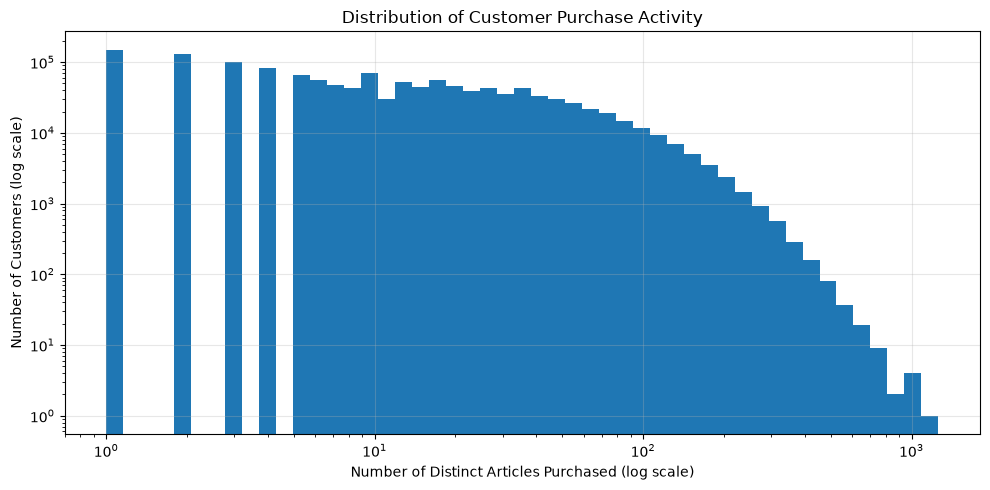

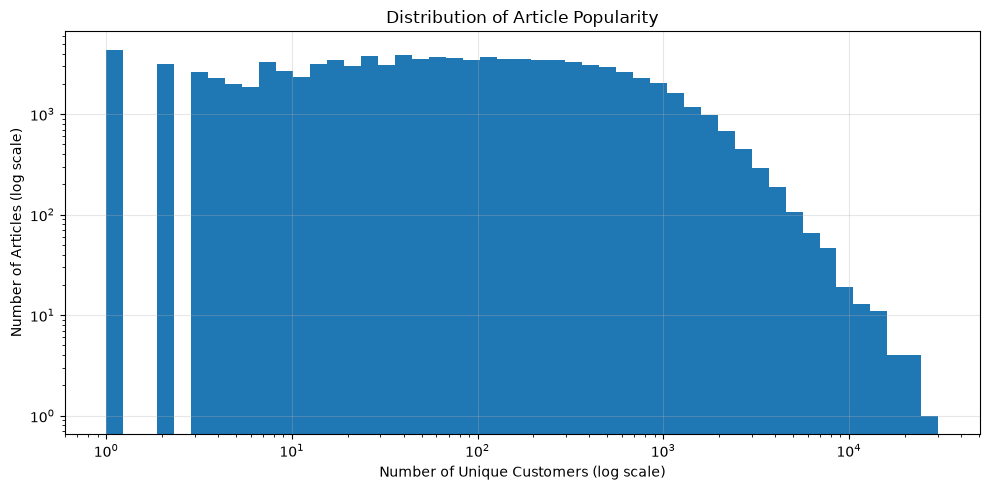

In [49]:
import matplotlib.pyplot as plt
import numpy as np

# Customer activity distribution
plt.figure(figsize=(10, 5))

customer_bins = np.logspace(
    np.log10(customer_activity["unique_articles"].min()),
    np.log10(customer_activity["unique_articles"].max()),
    50
)

plt.hist(
    customer_activity["unique_articles"],
    bins=customer_bins
)

plt.xscale("log")
plt.yscale("log")
plt.xlabel("Number of Distinct Articles Purchased (log scale)")
plt.ylabel("Number of Customers (log scale)")
plt.title("Distribution of Customer Purchase Activity")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# Article popularity distribution
plt.figure(figsize=(10, 5))

article_bins = np.logspace(
    np.log10(article_activity["unique_customers"].min()),
    np.log10(article_activity["unique_customers"].max()),
    50
)

plt.hist(
    article_activity["unique_customers"],
    bins=article_bins
)

plt.xscale("log")
plt.yscale("log")
plt.xlabel("Number of Unique Customers (log scale)")
plt.ylabel("Number of Articles (log scale)")
plt.title("Distribution of Article Popularity")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [50]:
# Customer activity groups
customer_activity["activity_group"] = pd.cut(
    customer_activity["unique_articles"],
    bins=[0, 1, 5, 10, 20, 50, 100, float("inf")],
    labels=[
        "1 article",
        "2–5",
        "6–10",
        "11–20",
        "21–50",
        "51–100",
        "100+"
    ]
)

customer_distribution = (
    customer_activity["activity_group"]
    .value_counts(sort=False)
    .rename("customer_count")
    .reset_index()
)

customer_distribution["percentage"] = (
    customer_distribution["customer_count"]
    / len(customer_activity) * 100
).round(2)

print("CUSTOMER ACTIVITY DISTRIBUTION")
display(customer_distribution)


# Article popularity groups
article_activity["popularity_group"] = pd.cut(
    article_activity["unique_customers"],
    bins=[0, 1, 5, 10, 50, 100, 500, 1000, float("inf")],
    labels=[
        "1 customer",
        "2–5",
        "6–10",
        "11–50",
        "51–100",
        "101–500",
        "501–1000",
        "1000+"
    ]
)

article_distribution = (
    article_activity["popularity_group"]
    .value_counts(sort=False)
    .rename("article_count")
    .reset_index()
)

article_distribution["percentage"] = (
    article_distribution["article_count"]
    / len(article_activity) * 100
).round(2)

print("ARTICLE POPULARITY DISTRIBUTION")
display(article_distribution)

CUSTOMER ACTIVITY DISTRIBUTION


,activity_group,customer_count,percentage
0,1 article,150296,11.37
1,2–5,376386,28.48
2,6–10,217838,16.48
3,11–20,213623,16.16
4,21–50,234833,17.77
5,51–100,94242,7.13
6,100+,34551,2.61


ARTICLE POPULARITY DISTRIBUTION


,popularity_group,article_count,percentage
0,1 customer,4372,4.44
1,2–5,9948,10.11
2,6–10,7793,7.92
3,11–50,24751,25.15
4,51–100,11729,11.92
5,101–500,25867,26.28
6,501–1000,7916,8.04
7,1000+,6040,6.14



# 12. Key Research Findings

## Dataset Overview
- The customer dataset contains 1,321,769 customers.
- The article catalogue contains approximately 98,416 articles.
- The transaction dataset contains over 31 million purchase records.

## Customer Behaviour
- Customers purchased an average of 19.33 distinct articles.
- The median number of distinct articles purchased was 8.
- Customer purchasing activity is highly uneven.
- A substantial proportion of customers purchased relatively few distinct articles.

## Product Popularity
- Article popularity follows a long-tail distribution.
- A relatively small number of products attract many customers.
- Many products have comparatively low interaction counts.

## Customer Demographics
- The average customer age is approximately 36.39 years.
- The median customer age is 32 years.
- Some customer demographic attributes contain missing values.

## Recommendation-System Implications
- The interaction matrix is extremely sparse, with approximately 99.98% sparsity.
- Popularity-based recommendations provide an important baseline.
- Collaborative filtering may face challenges with low-activity customers and less popular articles.
- Product metadata can provide additional information for content-based recommendations.
- A hybrid recommendation approach may help combine behavioural and product information.

## Conclusion
The exploratory analysis highlights substantial differences in customer activity and product popularity. These findings motivate the evaluation of popularity-based, collaborative filtering, content-based, and hybrid recommendation approaches.


In [51]:

# FINAL DATA QUALITY CHECKS

quality_checks = con.execute("""
SELECT
    COUNT(*) AS total_transactions,
    COUNT(DISTINCT customer_id) AS unique_customers,
    COUNT(DISTINCT article_id) AS unique_articles,
    COUNT(*) FILTER (WHERE customer_id IS NULL) AS missing_customer_ids,
    COUNT(*) FILTER (WHERE article_id IS NULL) AS missing_article_ids,
    COUNT(*) FILTER (WHERE price <= 0) AS invalid_prices,
    COUNT(*) FILTER (WHERE t_dat IS NULL) AS missing_dates
FROM transactions
""").df()

display(quality_checks.T)


,0
total_transactions,31788324
unique_customers,1362281
unique_articles,104547
missing_customer_ids,0
missing_article_ids,0
invalid_prices,0
missing_dates,0


In [52]:

referential_checks = con.execute("""
SELECT
    COUNT(*) FILTER (
        WHERE c.customer_id IS NULL
    ) AS unmatched_customer_ids,

    COUNT(*) FILTER (
        WHERE a.article_id IS NULL
    ) AS unmatched_article_ids

FROM transactions t

LEFT JOIN customers c
    ON t.customer_id = c.customer_id

LEFT JOIN articles a
    ON t.article_id = a.article_id
""").df()

display(referential_checks.T)


,0
unmatched_customer_ids,0
unmatched_article_ids,0
